# Visibility

Robot beacon localization project — Step 2. Map generation reuses `map_gen.py` (extracted from `random_map.ipynb`).

**The problem this notebook solves**: given a robot position $p$ (any point in free space) and a beacon position $b$ (any point on a wall), decide whether $p$ can see $b$.

It looks simple, but because **the beacons sit on the walls**, three geometric details have to be handled carefully:

1. **The wall a beacon sits on must not block the beacon itself.** The endpoint $b$ of segment $pb$ lies on a wall, so a naive segment-intersection test reports "blocked"; contact at that endpoint must be excluded.
2. **A beacon faces only one side of its wall.** A merged long wall segment may have free space on both sides (see Test 2 below); a beacon mounted on the wall surface can then only be seen from the side it faces.
3. **Grazing a wall corner.** When the line of sight passes exactly through a wall corner, we use the conservative rule agreed on earlier: **it counts as blocked**. Likewise, a line of sight collinear with a wall (sliding along the wall surface) counts as blocked.

Below we handle this with **exact predicates + a single geometric side probe**, without relying on an epsilon tolerance for the intersection test.

In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from map_gen import make_map, plot_map

# ---------------- parameters ----------------
GRID_W, GRID_H = 16, 12
TARGET_CELLS   = 120
HOLE_CELLS     = 10
SEED           = 42

# number of sample points per free cell in each direction (discretization of the robot position)
# use a power of 2 so sample coordinates are exact binary floats and the zero tests in the geometric predicates are reliable
RES = 4

cells, segments, corners, mids = make_map(GRID_W, GRID_H, TARGET_CELLS, HOLE_CELLS, SEED)
beacons = corners + mids
print(f'free cells       : {len(cells)}')
print(f'wall segments    : {len(segments)}')
print(f'beacon candidates: {len(beacons)}  ({len(corners)} corners + {len(mids)} midpoints)')

free cells       : 110
wall segments    : 72
beacon candidates: 144  (72 corners + 72 midpoints)


## 1. Sampling robot positions

The robot can be anywhere in free space, but verifying coverage needs a finite set of sample points. We split each free cell into `RES × RES` sub-cells
and take the center of each sub-cell as a sample point — these points lie strictly inside the cell and **never fall on a wall**, which makes the later geometric tests much simpler.

A larger `RES` gets closer to the continuous case, at a cost that grows as `RES²`. This is an explicit approximation in this project and is worth discussing in the report.

In [2]:
def sample_points(cells, res=RES):
    """Take res x res sample points inside each free cell (strictly in the cell interior)"""
    offs = [(i + 0.5) / res for i in range(res)]
    pts = [(x + dx, y + dy) for (x, y) in sorted(cells) for dx in offs for dy in offs]
    return np.array(pts, dtype=float)


P = sample_points(cells)
print(f'robot sample points: {len(P)}  (RES={RES}, {RES * RES} per cell)')

robot sample points: 1760  (RES=4, 16 per cell)


## 2. Geometric predicates

The core is the 2D cross product (orientation predicate):

$$\text{cross}(o, a, b) = (a_x - o_x)(b_y - o_y) - (a_y - o_y)(b_x - o_x)$$

Its sign says whether $b$ is to the left of, to the right of, or collinear with the ray $o\to a$. All coordinates are binary fractions (integers, `.5`, `1/RES` with RES a power of 2),
so floating-point arithmetic on them is **exact**, and the `== 0` collinearity test is reliable without any tolerance.

In [3]:
def cross(ox, oy, ax, ay, bx, by):
    """2D cross product; supports numpy broadcasting"""
    return (ax - ox) * (by - oy) - (ay - oy) * (bx - ox)


def on_seg_bbox(ax, ay, bx, by, qx, qy):
    """Given that q is collinear with ab, check whether q lies on segment ab (closed interval)"""
    return ((np.minimum(ax, bx) <= qx) & (qx <= np.maximum(ax, bx)) &
            (np.minimum(ay, by) <= qy) & (qy <= np.maximum(ay, by)))


def wall_arrays(segments):
    """Split wall segments into endpoint arrays for vectorized computation"""
    return (np.array([s[0] for s in segments], dtype=float),
            np.array([s[1] for s in segments], dtype=float))


W1, W2 = wall_arrays(segments)
print('wall endpoint arrays:', W1.shape, W2.shape)

wall endpoint arrays: (72, 2) (72, 2)


## 3. Visibility test

Robot $p$ sees beacon $b$ if and only if both of the following hold:

**(A) Side check** — the beacon faces the side where $p$ is.

Step a tiny distance $\varepsilon$ from $b$ in the direction of $p$; the resulting point must lie in free space.
This one step handles both the "free space on both sides of the wall" case and the "beacon at a convex corner" case. $\varepsilon$ is only used for a
cell-membership lookup (cells have unit size) and plays no part in the intersection test, so it is numerically very stable.

**(B) No wall crossing** — segment $pb$ intersects no wall except at its endpoint $b$. For each wall there are two cases:

- **The wall does not contain $b$**: standard segment-intersection test; **any** intersection (including merely touching an endpoint or grazing a wall corner) counts as blocked.
- **The wall contains $b$**: the two necessarily intersect at $b$, which is not an occlusion. The only blocking case here is when they are **collinear** (the line of sight slides along the wall surface).
  Since $b$ is on the wall, $b$ is the only intersection point as long as $p$ is not on the wall's line. So the test reduces to: is $p$ collinear with the wall?

This avoids shrinking segment endpoints by an epsilon, so the test is exact.

> Note: all walls in this project are axis-aligned and sample points lie strictly inside cells, so "line of sight collinear with a wall" can in fact never happen
> (it would require the robot's x or y to be exactly an integer). This branch is kept for correctness if non-axis-aligned maps are supported in the future.

In [4]:
EPS_SIDE = 1e-6   # side-probe step (only used for the cell-membership lookup)


def visible_from(b, P, cells, W1, W2):
    """Visibility of beacon b from the sample point set P; returns a boolean array (N,)"""
    bx, by = float(b[0]), float(b[1])
    Px, Py = P[:, 0], P[:, 1]

    # ---- (A) side check: b nudged toward p must land in free space ----
    dx, dy = Px - bx, Py - by
    dist = np.hypot(dx, dy)
    ok = dist > 0
    qx = bx + EPS_SIDE * np.divide(dx, dist, out=np.zeros_like(dx), where=ok)
    qy = by + EPS_SIDE * np.divide(dy, dist, out=np.zeros_like(dy), where=ok)
    cx, cy = np.floor(qx).astype(int), np.floor(qy).astype(int)
    side_ok = ok & np.array([(int(a), int(c)) in cells for a, c in zip(cx, cy)])

    # ---- (B) the line of sight does not cross any wall ----
    w1x, w1y = W1[:, 0][None, :], W1[:, 1][None, :]      # (1, K)
    w2x, w2y = W2[:, 0][None, :], W2[:, 1][None, :]
    px, py = Px[:, None], Py[:, None]                    # (N, 1)

    # d1: orientation of p relative to the wall; d2: orientation of b relative to the wall
    d1 = cross(w1x, w1y, w2x, w2y, px, py)                       # (N, K)
    d2 = cross(W1[:, 0], W1[:, 1], W2[:, 0], W2[:, 1], bx, by)   # (K,)
    # d3, d4: orientation of the two wall endpoints relative to the sight line p->b
    d3 = cross(px, py, bx, by, w1x, w1y)                 # (N, K)
    d4 = cross(px, py, bx, by, w2x, w2y)                 # (N, K)

    # proper intersection: strictly on opposite sides, both ways
    proper = (((d1 > 0) & (d2[None, :] < 0)) | ((d1 < 0) & (d2[None, :] > 0))) & \
             (((d3 > 0) & (d4 < 0)) | ((d3 < 0) & (d4 > 0)))
    # degenerate contact: collinear and on the segment — conservatively treated as blocked
    t1 = (d1 == 0) & on_seg_bbox(w1x, w1y, w2x, w2y, px, py)          # p lies on the wall
    t2 = (d2 == 0)[None, :] & on_seg_bbox(W1[:, 0], W1[:, 1],
                                          W2[:, 0], W2[:, 1], bx, by)[None, :]
    t3 = (d3 == 0) & on_seg_bbox(px, py, bx, by, w1x, w1y)            # grazes wall endpoint W1
    t4 = (d4 == 0) & on_seg_bbox(px, py, bx, by, w2x, w2y)            # grazes wall endpoint W2
    blocked_generic = proper | t1 | t2 | t3 | t4

    # walls containing b: blocked only if p is collinear with the wall (the sight line slides along it)
    contains_b = ((d2 == 0) &
                  on_seg_bbox(W1[:, 0], W1[:, 1], W2[:, 0], W2[:, 1], bx, by))  # (K,)
    blocked = np.where(contains_b[None, :], d1 == 0, blocked_generic)

    return side_ok & ~blocked.any(axis=1)


def visibility_matrix(beacons, P, cells, W1, W2):
    """Visibility matrix V[i, j] = whether sample point i can see beacon j, shape (N, M)"""
    return np.column_stack([visible_from(b, P, cells, W1, W2) for b in beacons])

## 4. Correctness tests

Check the visibility logic on two small hand-built maps.

**Test 1 — L-shaped map**: the reflex corner blocks the line of sight between the two arms, the most direct test of the wall-crossing check.

```
y=2  ■ . .
y=1  ■ . .        ■ = free cell
y=0  ■ ■ ■
     x=0 1 2
```

In [5]:
from map_gen import extract_wall_edges, merge_edges


def make_fixture(cells):
    segs = merge_edges(extract_wall_edges(cells))
    w1, w2 = wall_arrays(segs)

    def vis(b, p):
        return bool(visible_from(b, np.array([p], dtype=float), cells, w1, w2)[0])

    return segs, vis


def run_checks(vis, checks, name):
    print(f'--- {name} ---')
    for b, p, expect, why in checks:
        got = vis(b, p)
        print(f'[{"OK  " if got == expect else "FAIL"}] beacon={b} robot={p} '
              f'-> {got} (expect {expect})   # {why}')
    assert all(vis(b, p) == e for b, p, e, _ in checks), f'{name} failed'
    print()


L_cells = {(0, 0), (0, 1), (0, 2), (1, 0), (2, 0)}
L_segs, L_vis = make_fixture(L_cells)

run_checks(L_vis, [
    ((0.0, 0.5), (0.5, 0.5), True,  'same cell, beacon on the left wall'),
    ((0.0, 2.5), (0.5, 2.5), True,  'direct view inside the vertical arm'),
    ((0.5, 0.0), (0.5, 2.5), True,  'looking straight down the vertical arm at the bottom wall, path clear'),
    ((0.5, 3.0), (0.5, 0.5), True,  'looking straight up the vertical arm at the top wall, path clear'),
    ((2.0, 0.5), (0.5, 0.5), True,  'direct view along the horizontal-arm corridor'),
    ((3.0, 0.5), (2.5, 0.5), True,  'beacon on the wall at the right end of the horizontal arm'),
    ((0.0, 2.5), (2.5, 0.5), False, 'end of the horizontal arm to the top of the vertical arm — blocked by the reflex corner of the L'),
    ((0.0, 2.5), (1.5, 0.5), False, 'line of sight crosses the vertical wall x=1 — blocked'),
    ((1.0, 1.0), (0.5, 0.5), True,  'reflex corner point, visible from the vertical-arm side'),
    ((1.0, 1.0), (1.5, 0.5), True,  'same reflex corner point, also visible from the horizontal-arm side'),
], 'L-shaped map')

--- L-shaped map ---
[OK  ] beacon=(0.0, 0.5) robot=(0.5, 0.5) -> True (expect True)   # same cell, beacon on the left wall
[OK  ] beacon=(0.0, 2.5) robot=(0.5, 2.5) -> True (expect True)   # direct view inside the vertical arm
[OK  ] beacon=(0.5, 0.0) robot=(0.5, 2.5) -> True (expect True)   # looking straight down the vertical arm at the bottom wall, path clear
[OK  ] beacon=(0.5, 3.0) robot=(0.5, 0.5) -> True (expect True)   # looking straight up the vertical arm at the top wall, path clear
[OK  ] beacon=(2.0, 0.5) robot=(0.5, 0.5) -> True (expect True)   # direct view along the horizontal-arm corridor
[OK  ] beacon=(3.0, 0.5) robot=(2.5, 0.5) -> True (expect True)   # beacon on the wall at the right end of the horizontal arm
[OK  ] beacon=(0.0, 2.5) robot=(2.5, 0.5) -> False (expect False)   # end of the horizontal arm to the top of the vertical arm — blocked by the reflex corner of the L
[OK  ] beacon=(0.0, 2.5) robot=(1.5, 0.5) -> False (expect False)   # line of sight crosses th

**Test 2 — zigzag map**: tests "wall facing".

```
y=2  ■ ■ ■
y=1  ■ . ■        ■ = free cell
y=0  ■ ■ .
     x=0 1 2
```

On the line $x=2$, the wall segment for $y\in[0,1]$ has its free side on the **left** (from cell (1,0)), and the segment for $y\in[1,2]$ has its free side on the **right**
(from cell (2,1)). After merging they are **the same wall** $((2,0),(2,2))$, yet beacons mounted on it face opposite directions —
which is exactly why the side check is necessary.

In [6]:
Z_cells = {(0, 0), (1, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 1)}
Z_segs, Z_vis = make_fixture(Z_cells)

print('The merged long wall is indeed among the wall segments:',
      [s for s in Z_segs if s[0][0] == 2 and s[1][0] == 2])
print()

run_checks(Z_vis, [
    ((2.0, 0.5), (1.5, 0.5), True,  'beacon free side on the left, robot on the left -> visible'),
    ((2.0, 0.5), (2.5, 1.5), False, 'same beacon, robot on the right of the wall -> cannot see the back side'),
    ((2.0, 1.5), (2.5, 1.5), True,  'beacon free side on the right, robot on the right -> visible'),
    ((2.0, 1.5), (1.5, 0.5), False, 'same beacon, robot on the left of the wall -> cannot see the back side'),
], 'zigzag map (wall facing)')

print('all predicate tests passed')

The merged long wall is indeed among the wall segments: [((2, 0), (2, 2))]

--- zigzag map (wall facing) ---
[OK  ] beacon=(2.0, 0.5) robot=(1.5, 0.5) -> True (expect True)   # beacon free side on the left, robot on the left -> visible
[OK  ] beacon=(2.0, 0.5) robot=(2.5, 1.5) -> False (expect False)   # same beacon, robot on the right of the wall -> cannot see the back side
[OK  ] beacon=(2.0, 1.5) robot=(2.5, 1.5) -> True (expect True)   # beacon free side on the right, robot on the right -> visible
[OK  ] beacon=(2.0, 1.5) robot=(1.5, 0.5) -> False (expect False)   # same beacon, robot on the left of the wall -> cannot see the back side

all predicate tests passed


## 5. Visible region of a single beacon

Pick a few beacons on the random map and plot the sample points each of them can see. Green = visible, gray = not visible.

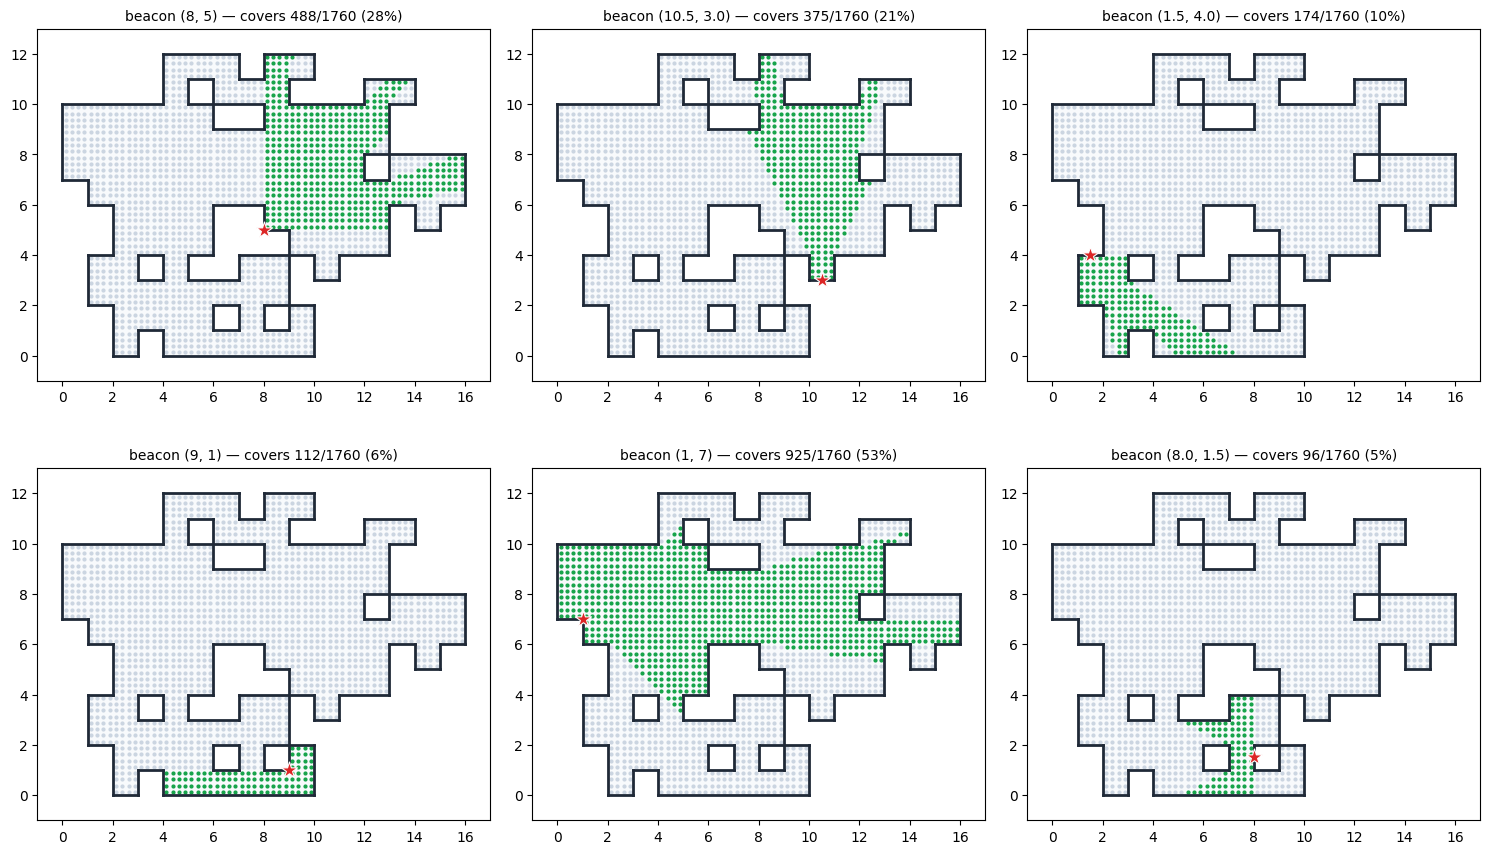

In [7]:
def plot_visible_region(b, P, vis, cells, segments, ax, title=''):
    for (x, y) in cells:
        ax.add_patch(Rectangle((x, y), 1, 1, facecolor='#f8fafc', edgecolor='none'))
    ax.scatter(P[~vis, 0], P[~vis, 1], s=4, color='#cbd5e1', zorder=2)
    ax.scatter(P[vis, 0], P[vis, 1], s=4, color='#16a34a', zorder=2)
    for (x1, y1), (x2, y2) in segments:
        ax.plot([x1, x2], [y1, y2], color='#1f2937', linewidth=2, zorder=3)
    ax.scatter([b[0]], [b[1]], s=150, marker='*', color='#dc2626',
               edgecolor='white', linewidth=0.8, zorder=4)
    xs = [x for x, _ in cells]; ys = [y for _, y in cells]
    ax.set_xlim(min(xs) - 1, max(xs) + 2)
    ax.set_ylim(min(ys) - 1, max(ys) + 2)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=10)


picks = np.random.default_rng(0).choice(len(beacons), size=6, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for idx, ax in zip(picks, axes.flat):
    b = beacons[idx]
    vis = visible_from(b, P, cells, W1, W2)
    plot_visible_region(b, P, vis, cells, segments, ax,
                        title=f'beacon {tuple(b)} — covers {vis.sum()}/{len(P)} '
                              f'({100 * vis.mean():.0f}%)')
plt.tight_layout()
plt.show()

## 6. Full visibility matrix

Compute visibility for all sample points × all candidate beacons. This matrix is the **only input** to the next optimization step —
the minimum-beacon problem is the minimum multi-cover on it: "every row must be covered by at least 3 selected columns".

In [8]:
import time

t0 = time.time()
V = visibility_matrix(beacons, P, cells, W1, W2)
print(f'visibility matrix {V.shape} computed in {time.time() - t0:.2f}s')
print(f'density: {100 * V.mean():.1f}% of (point, beacon) pairs are visible')

per_beacon = V.sum(axis=0)
per_point = V.sum(axis=1)
print(f'\ncoverage per beacon      : min={per_beacon.min()}  '
      f'median={int(np.median(per_beacon))}  max={per_beacon.max()}')
print(f'visible beacons per point: min={per_point.min()}  '
      f'median={int(np.median(per_point))}  max={per_point.max()}')

# feasibility: using ALL candidate beacons, can every point see >= 3 of them?
n_bad = int((per_point < 3).sum())
print(f'\npoints seeing < 3 beacons (using ALL candidates): {n_bad}')
print('=> the candidate set is sufficient; the minimization problem is feasible' if n_bad == 0
      else '=> some points cannot be satisfied; the candidates need densifying (see the discussion at the end)')

visibility matrix (1760, 144) computed in 0.41s
density: 24.3% of (point, beacon) pairs are visible

coverage per beacon      : min=32  median=393  max=1054
visible beacons per point: min=5  median=35  max=60

points seeing < 3 beacons (using ALL candidates): 0
=> the candidate set is sufficient; the minimization problem is feasible


## 7. Coverage-count heatmaps

Left: how many beacons each sample point can see when **all** candidate beacons are used — an upper bound on coverage.

Right: the effect of 12 randomly chosen beacons; red areas see < 3 beacons, so the robot **cannot localize** there.
Random placement leaves large blind areas, which is exactly why the next optimization step is needed.

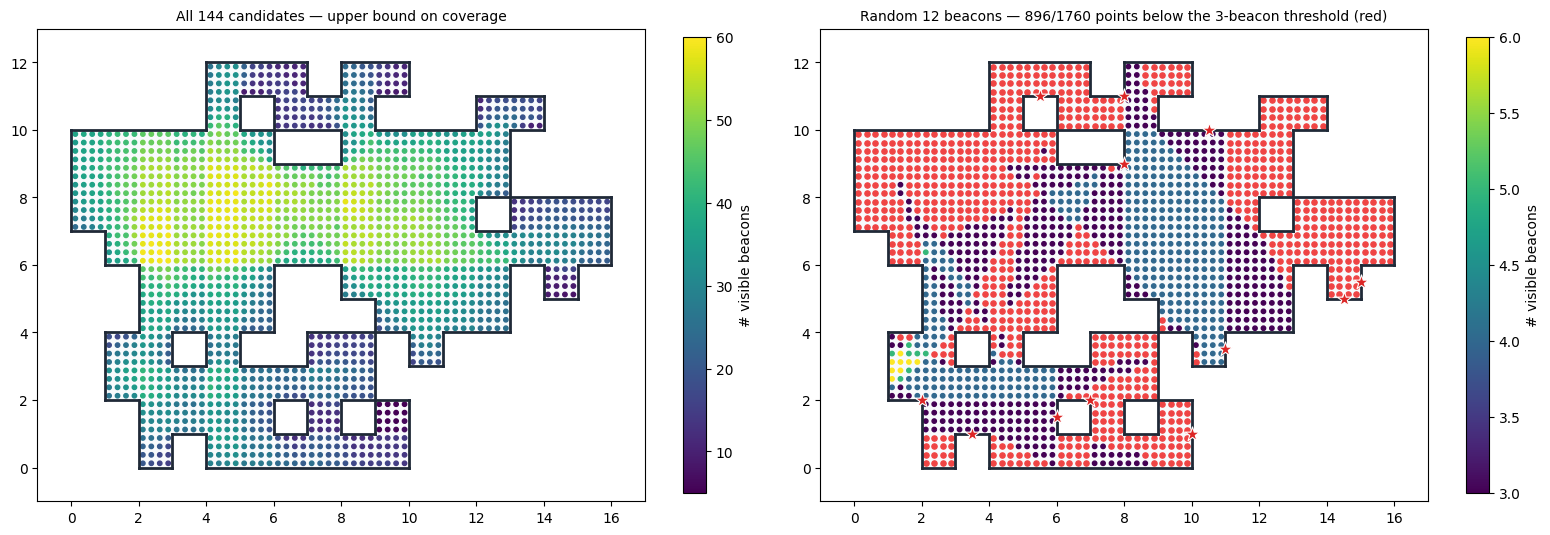

In [9]:
def plot_coverage(P, counts, cells, segments, ax, chosen=None, title=''):
    for (x, y) in cells:
        ax.add_patch(Rectangle((x, y), 1, 1, facecolor='#f8fafc', edgecolor='none'))
    bad = counts < 3
    if bad.any():
        ax.scatter(P[bad, 0], P[bad, 1], s=14, color='#ef4444', zorder=2)
    if (~bad).any():
        sc = ax.scatter(P[~bad, 0], P[~bad, 1], c=counts[~bad], s=10,
                        cmap='viridis', zorder=2)
        plt.colorbar(sc, ax=ax, shrink=0.8, label='# visible beacons')
    for (x1, y1), (x2, y2) in segments:
        ax.plot([x1, x2], [y1, y2], color='#1f2937', linewidth=2, zorder=3)
    if chosen is not None and len(chosen):
        cb = np.array([beacons[i] for i in chosen], dtype=float)
        ax.scatter(cb[:, 0], cb[:, 1], s=120, marker='*', color='#dc2626',
                   edgecolor='white', linewidth=0.8, zorder=4)
    xs = [x for x, _ in cells]; ys = [y for _, y in cells]
    ax.set_xlim(min(xs) - 1, max(xs) + 2)
    ax.set_ylim(min(ys) - 1, max(ys) + 2)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=10)


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_coverage(P, per_point, cells, segments, axes[0],
              title=f'All {len(beacons)} candidates — upper bound on coverage')

sub = np.random.default_rng(7).choice(len(beacons), size=12, replace=False)
sub_counts = V[:, sub].sum(axis=1)
plot_coverage(P, sub_counts, cells, segments, axes[1], chosen=sub,
              title=f'Random 12 beacons — {int((sub_counts < 3).sum())}/{len(P)} '
                    f'points below the 3-beacon threshold (red)')
plt.tight_layout()
plt.show()

## 8. Export

Save the visibility matrix and the geometry so the next optimization notebook can load them directly instead of recomputing.

In [10]:
np.savez_compressed(
    'visibility_data.npz',
    V=V,
    P=P,
    beacons=np.array(beacons, dtype=float),
    cells=np.array(sorted(cells), dtype=int),
    W1=W1, W2=W2,
    meta=np.array([GRID_W, GRID_H, TARGET_CELLS, HOLE_CELLS, SEED, RES]),
)
print('saved -> visibility_data.npz')

saved -> visibility_data.npz


## Summary and next steps

**Done**: an exact line-of-sight test (handling three degenerate cases: beacons on walls, wall facing, and corner grazing),
visualization of visible regions, and the full visibility matrix `V`.

**Known approximations and trade-offs** (good material for the report):

- *Discretized robot positions*: only the `RES × RES` sample points per cell are verified; other positions inside a cell are not. Increasing `RES` converges,
  but a rigorous guarantee needs the continuous version: a visibility decomposition (cutting the free space into cells along critical lines of sight).
- *Discretized beacon positions*: only wall corners and wall-segment midpoints are used. In theory reflex corners are the best positions, but "one midpoint per wall segment" is not necessarily enough;
  if needed, sampling along the walls can be densified (which enlarges the problem).
- *Conservative corner grazing*: lines of sight that graze a wall corner or slide along a wall count as blocked, so the resulting beacon layouts are conservative (on the safe side).

**Next step (optimization)**: find the minimum number of beacons on `V`.

1. Greedy: in each round pick the beacon that "moves the most under-covered points one step forward"; this has an $O(\log n)$ approximation guarantee
2. ILP: $\min \sum_j x_j$ s.t. $\sum_j V_{ij} x_j \ge 3\ \forall i$, solved to optimality with OR-Tools at small scale and compared with greedy
3. Across many random maps, relate the number of beacons to map area / number of reflex corners